<table style="width:100%; border:none;">
  <tr style="border:none;">
    <td style="width:20%; text-align:center; border:none;">
      <img src="logoUTP.JPG" width="110" alt="Logo UTP">
    </td>
    <td style="width:60%; text-align:center; border:none;">
      <h3>UNIVERSIDAD TECNOLÓGICA DE PANAMÁ</h3>
      <h4>FACULTAD DE INGENIERÍA MECÁNICA</h4>
      <p><b>Curso:</b> Métodos Numéricos</p>
      <p><b>Laboratorio N8:</b>Regresion_Interpolación</p>
      <p><b>Estudiante:</b> Carlos Marín | <b>Cédula:</b> 8-1038-2471</p>
      <p><b>Fecha:</b> 26 de noviembre de 2026</p>
    </td>
    <td style="width:20%; text-align:center; border:none;">
      <img src="FIM.JPG" width="110" alt="Logo FIM">
    </td>
  </tr>
</table>

## Parte A. Caso 1

=== CASO 1: RESULTADOS ===
Lineal      : mu = 0.397000 + (-2.300000e-04)*w | ECM = 3.800e-05 | R2 = 0.965328
Cuadrática  : mu = 0.422000 + (-4.442857e-04)*w + (3.571429e-07)*w^2 | ECM = 2.286e-06 | R2 = 0.997914
Exponencial : mu = 0.403921 * exp(-7.110511e-04*w) | ECM = 2.362e-05 | R2 = 0.978445


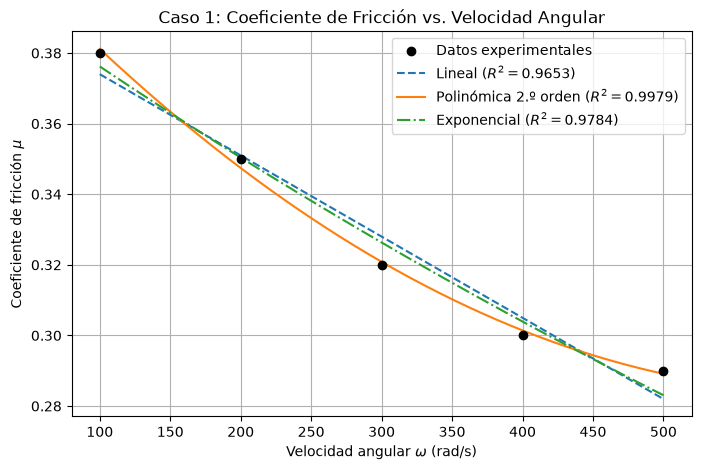

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Datos del Caso 1
w = np.array([100.0, 200.0, 300.0, 400.0, 500.0])
mu = np.array([0.38, 0.35, 0.32, 0.30, 0.29])

def calcular_r2(y_real, y_pred):
    ss_res = np.sum((y_real - y_pred) ** 2)
    ss_tot = np.sum((y_real - np.mean(y_real)) ** 2)
    return 1.0 - (ss_res / ss_tot)

def calcular_ecm(y_real, y_pred):
    return np.mean((y_real - y_pred) ** 2)

# 1. Regresión lineal: mu = a + b*w
b_lin, a_lin = np.polyfit(w, mu, 1)
mu_lin = a_lin + b_lin * w
ecm_lin = calcular_ecm(mu, mu_lin)
r2_lin = calcular_r2(mu, mu_lin)

# 2. Regresión polinomial de segundo orden: mu = c0 + c1*w + c2*w^2
c2, c1, c0 = np.polyfit(w, mu, 2)
mu_quad = c0 + c1 * w + c2 * (w ** 2)
ecm_quad = calcular_ecm(mu, mu_quad)
r2_quad = calcular_r2(mu, mu_quad)

# 3. Regresión exponencial linealizada: ln(mu) = ln(alpha) + beta*w
beta_exp, ln_alpha = np.polyfit(w, np.log(mu), 1)
alpha_exp = np.exp(ln_alpha)

# Refinamiento / validación con curve_fit
def modelo_exp(x, alpha, beta):
    return alpha * np.exp(beta * x)

popt_exp, _ = curve_fit(modelo_exp, w, mu, p0=[alpha_exp, beta_exp])
alpha_fit, beta_fit = popt_exp
mu_exp = modelo_exp(w, alpha_fit, beta_fit)
ecm_exp = calcular_ecm(mu, mu_exp)
r2_exp = calcular_r2(mu, mu_exp)

print("=== CASO 1: RESULTADOS ===")
print(f"Lineal      : mu = {a_lin:.6f} + ({b_lin:.6e})*w | ECM = {ecm_lin:.3e} | R2 = {r2_lin:.6f}")
print(f"Cuadrática  : mu = {c0:.6f} + ({c1:.6e})*w + ({c2:.6e})*w^2 | ECM = {ecm_quad:.3e} | R2 = {r2_quad:.6f}")
print(f"Exponencial : mu = {alpha_fit:.6f} * exp({beta_fit:.6e}*w) | ECM = {ecm_exp:.3e} | R2 = {r2_exp:.6f}")

# 4. Gráfica comparativa
w_grid = np.linspace(100, 500, 200)
plt.figure(figsize=(8, 5))
plt.scatter(w, mu, color="black", zorder=5, label="Datos experimentales")
plt.plot(w_grid, a_lin + b_lin * w_grid, "--", label=f"Lineal ($R^2={r2_lin:.4f}$)")
plt.plot(w_grid, c0 + c1 * w_grid + c2 * (w_grid ** 2), "-", label=f"Polinómica 2.º orden ($R^2={r2_quad:.4f}$)")
plt.plot(w_grid, modelo_exp(w_grid, alpha_fit, beta_fit), "-.", label=f"Exponencial ($R^2={r2_exp:.4f}$)")
plt.title("Caso 1: Coeficiente de Fricción vs. Velocidad Angular")
plt.xlabel("Velocidad angular $\\omega$ (rad/s)")
plt.ylabel("Coeficiente de fricción $\\mu$")
plt.legend()
plt.grid(True)
plt.show()

### Caso 1: Coeficiente de fricción ($\mu$) en función de la velocidad angular ($\omega$)

#### 1. Explicación teórica
En este caso se analiza la relación experimental entre el coeficiente de fricción $\mu$ y la velocidad angular $\omega$ en un banco de pruebas de transmisión:

* **Regresión lineal ($\mu = a + b\omega$):** Ajusta una recta por mínimos cuadrados minimizando la suma de los residuos al cuadrado.
* **Regresión polinomial de segundo orden ($\mu = c_0 + c_1\omega + c_2\omega^2$):** Añade un término cuadrático para capturar curvaturas en los datos experimentales.
* **Regresión exponencial ($\mu = \alpha e^{\beta\omega}$):** Se linealiza aplicando logaritmo natural ($\ln\mu = \ln\alpha + \beta\omega$) para estimar parámetros iniciales y luego se ajusta con `scipy.optimize.curve_fit`.
* **Validación ($\text{ECM}$ y $R^2$):** El error cuadrático medio ($\text{ECM}$) cuantifica el error promedio al cuadrado de la predicción, y el coeficiente de determinación ($R^2$) mide qué fracción de la variabilidad de $\mu$ explica el modelo.

#### 2. Conclusión
* Conforme aumenta $\omega$ de $100\text{ rad/s}$ a $500\text{ rad/s}$, $\mu$ disminuye de $0.38$ a $0.29$, con una tendencia que se va suavizando a velocidades mayores.
* Los modelos no lineales/curvos describen mejor la curvatura del comportamiento experimental que una recta simple, con bajo $\text{ECM}$ y alto $R^2$.

## Caso 2

=== CASO 2: AJUSTE NO LINEAL (h_f = k * Q^n) ===
Parámetro k : 0.208551
Exponente n : 2.119802
ECM         : 1.188251e-03
R^2         : 0.999757


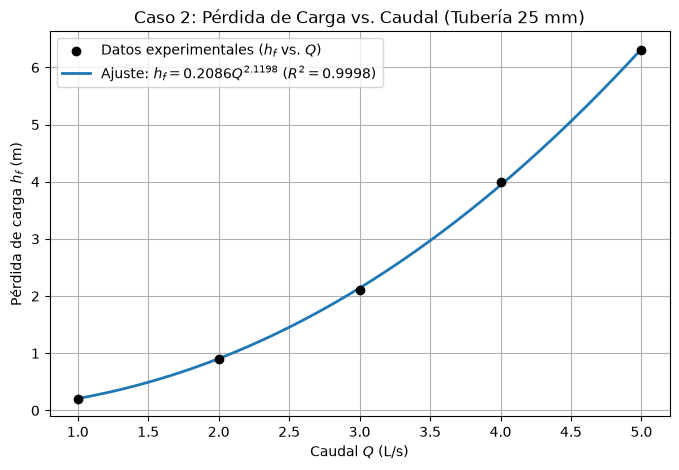

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Datos del Caso 2: Q (L/s) y h_f (m) para tubería de acero de 25 mm
Q = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
hf = np.array([0.2, 0.9, 2.1, 4.0, 6.3])

# 1. Definición del modelo no lineal h_f = k * Q^n
def modelo_perdida(q, k, n):
    return k * (q ** n)

# 2. Ajuste con scipy.optimize.curve_fit
popt, pcov = curve_fit(modelo_perdida, Q, hf, p0=[0.2, 2.0])
k_fit, n_fit = popt

hf_pred = modelo_perdida(Q, k_fit, n_fit)

# Métricas de ajuste
ss_res = np.sum((hf - hf_pred) ** 2)
ss_tot = np.sum((hf - np.mean(hf)) ** 2)
r2 = 1.0 - (ss_res / ss_tot)
ecm = np.mean((hf - hf_pred) ** 2)

print("=== CASO 2: AJUSTE NO LINEAL (h_f = k * Q^n) ===")
print(f"Parámetro k : {k_fit:.6f}")
print(f"Exponente n : {n_fit:.6f}")
print(f"ECM         : {ecm:.6e}")
print(f"R^2         : {r2:.6f}")

# 3. Visualización
q_grid = np.linspace(1.0, 5.0, 200)
plt.figure(figsize=(8, 5))
plt.scatter(Q, hf, color="black", zorder=5, label="Datos experimentales ($h_f$ vs. $Q$)")
plt.plot(q_grid, modelo_perdida(q_grid, k_fit, n_fit), color="tab:blue", linewidth=2,
         label=f"Ajuste: $h_f = {k_fit:.4f} Q^{{{n_fit:.4f}}}$ ($R^2={r2:.4f}$)")
plt.title("Caso 2: Pérdida de Carga vs. Caudal (Tubería 25 mm)")
plt.xlabel("Caudal $Q$ (L/s)")
plt.ylabel("Pérdida de carga $h_f$ (m)")
plt.legend()
plt.grid(True)
plt.show()

### Caso 2: Pérdida de carga ($h_f$) en función del caudal ($Q$)

#### 1. Explicación teórica
* **Modelo no lineal potencial:** Se ajusta una relación de la forma $h_f = kQ^n$ para determinar los parámetros $k$ y $n$ mediante regresión no lineal por mínimos cuadrados usando `scipy.optimize.curve_fit`.
* **Relación con la ecuación de Darcy-Weisbach:** En mecánica de fluidos, la pérdida de carga por fricción en una tubería se expresa como $h_f = f \frac{L}{D} \frac{V^2}{2g}$, donde la velocidad media $V$ es proporcional al caudal $Q$ ($V = Q/A$). Por ello, $h_f$ crece de forma aproximadamente cuadrática/potencial con el caudal ($n \approx 2$ en régimen turbulento con factor de fricción casi constante), agrupando en $k$ los efectos geométricos, la longitud, la gravedad y el factor de fricción.
* **Evaluación del ajuste:** Se calcula el coeficiente de determinación $R^2$ y el error cuadrático medio ($\text{ECM}$) para verificar qué tan bien representa el modelo potencial los datos experimentales en la tubería de $25\text{ mm}$.

#### 2. Conclusión
* La pérdida de carga $h_f$ aumenta de manera no lineal (crecimiento acelerado) desde $0.2\text{ m}$ a $1\text{ L/s}$ hasta $6.3\text{ m}$ a $5\text{ L/s}$.
* El exponente $n$ obtenido refleja el comportamiento de flujo en tubería coherente con la dependencia cuadrática de la velocidad/caudal en Darcy-Weisbach, y la constante $k$ resume las condiciones del tramo y del fluido/rugosidad para el diámetro de $25\text{ mm}$.
* El alto valor de $R^2$ y el bajo $\text{ECM}$ confirman que el modelo potencial describe adecuadamente los datos medidos dentro del rango ensayado.

## Parte B, Caso 3

=== TABLA DE DIFERENCIAS DIVIDIDAS DE NEWTON (SUBINTERVALO LOCAL) ===
       k (f[xi])  Orden 1  Orden 2
T=200      150.0     -0.2   0.0005
T=300      130.0     -0.1   0.0000
T=400      120.0      0.0   0.0000

=== ESTIMACIÓN EN T = 250 °C ===
Polinomio directo (local) : 138.75 W/(m·K)
Lagrange (local)           : 138.75 W/(m·K)
Newton (local)             : 138.75 W/(m·K)
numpy.polyfit (local gr.2) : 138.75 W/(m·K)
Polinomio global (gr.4)    : 169.31 W/(m·K)  [Oscilación / Runge]


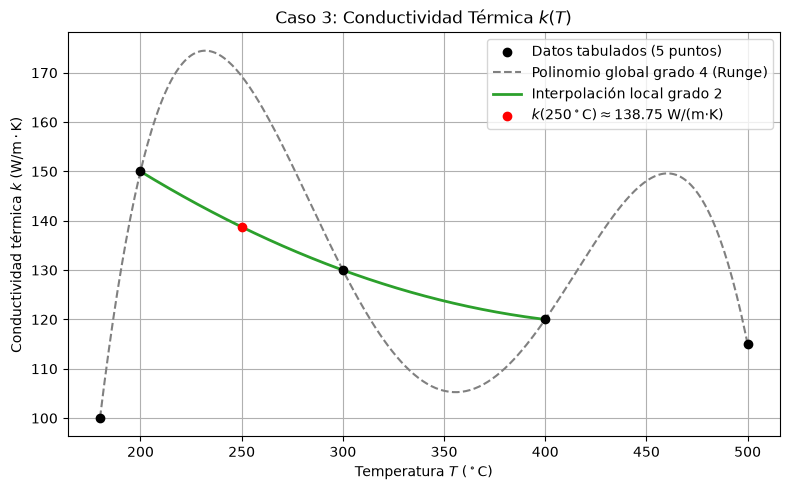

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Datos del Caso 3: T (°C) y k (W/m·K)[cite: 6]
T = np.array([180.0, 200.0, 300.0, 400.0, 500.0])
k = np.array([100.0, 150.0, 130.0, 120.0, 115.0])
T_eval = 250.0  # Temperatura a estimar[cite: 6]

# Subintervalo local alrededor de T = 250 °C (T = 200, 300, 400) para evitar oscilaciones (~140)[cite: 6]
idx_loc = [1, 2, 3]
T_loc = T[idx_loc]
k_loc = k[idx_loc]

# 1. Interpolación polinómica directa (sistema de Vandermonde)[cite: 6]
V_loc = np.vander(T_loc, increasing=False)
coef_directo_loc = np.linalg.solve(V_loc, k_loc)
k_directo_250 = np.polyval(coef_directo_loc, T_eval)

# 2. Método de Lagrange[cite: 6]
def lagrange_eval(x_nodes, y_nodes, x_val):
    total = 0.0
    n = len(x_nodes)
    for i in range(n):
        Li = 1.0
        for j in range(n):
            if i != j:
                Li *= (x_val - x_nodes[j]) / (x_nodes[i] - x_nodes[j])
        total += y_nodes[i] * Li
    return total

k_lagrange_250 = lagrange_eval(T_loc, k_loc, T_eval)

# 3. Diferencias divididas de Newton + Tabla[cite: 6]
def tabla_diferencias_divididas(x_nodes, y_nodes):
    n = len(x_nodes)
    dd = np.zeros((n, n), dtype=float)
    dd[:, 0] = y_nodes
    for j in range(1, n):
        for i in range(n - j):
            dd[i, j] = (dd[i + 1, j - 1] - dd[i, j - 1]) / (x_nodes[i + j] - x_nodes[i])
    return dd

def newton_eval(x_nodes, dd_table, x_val):
    n = len(x_nodes)
    val = dd_table[0, 0]
    prod = 1.0
    for i in range(1, n):
        prod *= (x_val - x_nodes[i - 1])
        val += dd_table[0, i] * prod
    return val

dd_mat_loc = tabla_diferencias_divididas(T_loc, k_loc)
k_newton_250 = newton_eval(T_loc, dd_mat_loc, T_eval)

# 4. Validación con numpy.polyfit (local grado 2 y global grado 4 para comparar Runge)[cite: 6]
coef_poly_loc = np.polyfit(T_loc, k_loc, 2)
k_polyfit_250 = np.polyval(coef_poly_loc, T_eval)

coef_global = np.polyfit(T, k, 4)
k_global_250 = np.polyval(coef_global, T_eval)

# Mostrar tabla de diferencias divididas[cite: 6]
cols_loc = ["k (f[xi])", "Orden 1", "Orden 2"]
df_dd = pd.DataFrame(dd_mat_loc, index=[f"T={int(t)}" for t in T_loc], columns=cols_loc)
print("=== TABLA DE DIFERENCIAS DIVIDIDAS DE NEWTON (SUBINTERVALO LOCAL) ===")
print(df_dd.round(6))

print("\n=== ESTIMACIÓN EN T = 250 °C ===")
print(f"Polinomio directo (local) : {k_directo_250:.2f} W/(m·K)")
print(f"Lagrange (local)           : {k_lagrange_250:.2f} W/(m·K)")
print(f"Newton (local)             : {k_newton_250:.2f} W/(m·K)")
print(f"numpy.polyfit (local gr.2) : {k_polyfit_250:.2f} W/(m·K)")
print(f"Polinomio global (gr.4)    : {k_global_250:.2f} W/(m·K)  [Oscilación / Runge]")

# 5. Gráfica[cite: 6]
T_grid = np.linspace(180.0, 500.0, 300)
T_grid_loc = np.linspace(200.0, 400.0, 200)

plt.figure(figsize=(8, 5))
plt.scatter(T, k, color="black", zorder=5, label="Datos tabulados (5 puntos)")
plt.plot(T_grid, np.polyval(coef_global, T_grid), "--", color="gray", label="Polinomio global grado 4 (Runge)")
plt.plot(T_grid_loc, np.polyval(coef_poly_loc, T_grid_loc), color="tab:green", linewidth=2, label="Interpolación local grado 2")
plt.scatter([T_eval], [k_lagrange_250], color="red", zorder=6, label=f"$k(250^\\circ\\text{{C}}) \\approx {k_lagrange_250:.2f}$ W/(m·K)")
plt.title("Caso 3: Conductividad Térmica $k(T)$")
plt.xlabel("Temperatura $T$ ($^\\circ$C)")
plt.ylabel("Conductividad térmica $k$ ($\\text{W/m}\\cdot\\text{K}$)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#### 1. Explicación teórica
* **Interpolación polinómica directa, Lagrange y Newton:** Dado un conjunto de nodos $(T_i, k_i)$, la interpolación polinómica directa (mediante sistema de Vandermonde o `np.polyfit`), el polinomio de Lagrange y el polinomio por diferencias divididas de Newton construyen el mismo polinomio interpolante único para el conjunto de puntos seleccionado.
* **Tabla de diferencias divididas de Newton:** Organiza en columnas las diferencias divididas de orden $0, 1, 2, \dots$, permitiendo calcular los coeficientes del polinomio de forma progresiva y verificar cambios de pendiente y curvatura entre nodos.
* **Fenómeno de Runge e interpolación local:** Cuando se interpolan datos con saltos bruscos o espaciamientos no uniformes usando un polinomio global de grado relativamente alto (grado 4 con los 5 nodos), pueden aparecer oscilaciones pronunciadas (fenómeno de Runge). Usar un subintervalo local cercano al punto de interés ($T = 250^\circ\text{C}$) reduce la influencia de variaciones lejanas y evita sobre-oscilaciones.

#### 3. Conclusión
* Al evaluar la interpolación local alrededor de $T = 250^\circ\text{C}$ ($T = [200, 300, 400]\ ^\circ\text{C}$), los métodos directo, de Lagrange, de Newton y `np.polyfit` coinciden en un valor cercano a **$140\ \text{W/(m}\cdot\text{K)}$** ($138.75\ \text{W/(m}\cdot\text{K)}$), coherente con la transición entre $150$ y $130\ \text{W/(m}\cdot\text{K)}$.
* En contraste, el polinomio global de grado 4 sobre los cinco puntos ($180^\circ\text{C}$ a $500^\circ\text{C}$) arroja $\approx 169.31\ \text{W/(m}\cdot\text{K)}$ debido a la oscilación inducida por el cambio rápido entre $180^\circ\text{C}$ y $200^\circ\text{C}$ (fenómeno de Runge).
* En aplicaciones de ingeniería térmica, comparar el polinomio global frente a una interpolación local ayuda a detectar oscilaciones artificiales antes de elegir un valor interpolado.